# Fuel-based emissions: MRV factor sensitivity

**What this notebook does.** It takes the ship-specific fuel intensities from the EMSA THETIS-MRV,
converts them to well-to-wake (WTW) CO₂e factors comparable to the UK DESNZ factor the case
analyses use (0.020 kg CO₂e per tonne-km for container ships), and shows how the Case 1 and
Case 2 headline numbers — emissions per tonne of US supply — change if the MRV distribution
replaces the single UK DESNZ value.

**Why it matters.** The case analyses multiply distance × factor for every sea leg. The UK DESNZ
factor is a fleet average; MRV data lets us check whether it overstates or understates the
ocean leg for the container ships actually serving these routes, and how much the factor choice
swings the findings.

**How it's organised.** Section 2 recaps the MRV distribution from the validation notebook.
Section 3 derives WTW-equivalent factors from MRV's tank-to-wake CO₂. Sections 4–5 substitute
those factors into the Case 1 and Case 2 pipelines and compare. Section 6 checks whether the
per-ship variation within the MRV data is larger than the factor choice.

**To run:** set `ANALYST_DATABASE_URL` in `analysis/.env`, then run all cells. It reads; it
never writes to the database.

## 1. Setup

In [1]:

import matplotlib.pyplot as plt
import polars as pl
from shockt_engine import load_leg_factors, select_factors, window_summary

from shockt_analysis import cases, core
from shockt_analysis.settings import REPO_ROOT, get_settings

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_float_precision(4)

NM_TO_KM = 1.852

CASE1_DIR = REPO_ROOT / "inputs" / "cases" / "tariffs_2025"
SERVER_CODES = ["847150"]
GEAR_CODES = ["850421", "850422", "850423", "850433", "850434", "853720"]
ALL_CODES = SERVER_CODES + GEAR_CODES

In [2]:
with core.connect(get_settings()) as conn:
    mrv = core.ship_fuel_intensities(conn)
    factor_rows = core.factors(conn)
    supply = core.supply(conn, ALL_CODES)
    node_weights = core.node_weights(conn, ALL_CODES)
    observed_sea = core.observed_sea(conn)
    distances = {seed: core.distances(conn, seed) for seed in ("sea", "air", "road", "rail")}
    crossing_plants = core.crossing_plants(conn)
    loads = core.current_loads(
        conn,
        ["thetis_mrv", "climatetrace_voyages", "census_hs", "census_porths",
         "census_statehs", "bts_transborder", "uk_ghg_conversion_factors",
         "epa_ghg_transport_factors", "epa_ghg_gwp"],
    )

leg_factors = select_factors(factor_rows, load_leg_factors())
assumed_ocean = leg_factors["ocean"]
windows = cases.load_windows(CASE1_DIR / "shock_windows.yaml")

print(f"Assumed ocean factor: {assumed_ocean.wtw_kg_co2e_per_tkm} kg CO₂e/tkm "
      f"({assumed_ocean.variant}, {assumed_ocean.source})")
print(f"MRV rows: {mrv.height:,}")
print(f"Supply rows: {supply.height:,}; months {supply['month'].min()} to {supply['month'].max()}")
loads

Assumed ocean factor: 0.01977 kg CO₂e/tkm (Cargo ship / Container ship / Average, uk_desnz)
MRV rows: 12,829
Supply rows: 5,563; months 2022-01-01 to 2026-08-01


dataset,partitions,latest_load,code_versions
str,i64,str,str
"""bts_transborder""",56,"""2026-10-24 16:04:20.860777+00""","""1a5019b"""
"""census_hs""",1064,"""2026-10-26 13:32:57.914027+00""","""1a5019b-dirty, 1f10182-dirty, …"
"""census_porths""",952,"""2026-10-24 15:56:25.999037+00""","""1f10182-dirty, e097cd6"""
"""census_statehs""",952,"""2026-10-24 15:55:21.046393+00""","""1f10182-dirty, e097cd6"""
"""climatetrace_voyages""",5,"""2026-10-12 22:52:15.201059+00""","""20b5845"""
"""epa_ghg_gwp""",1,"""2026-10-12 22:52:51.50207+00""","""20b5845"""
"""epa_ghg_transport_factors""",1,"""2026-10-12 22:52:48.687086+00""","""20b5845"""
"""thetis_mrv""",1,"""2026-10-23 21:53:59.104058+00""","""9ed641f-dirty"""
"""uk_ghg_conversion_factors""",1,"""2026-10-12 22:52:36.02174+00""","""20b5845"""


## 2. MRV distribution recap

Container ships matched to Climate TRACE voyages, with a valid transport-work intensity.
MRV reports tank-to-wake (TTW) CO₂ only, not CO₂e; the UK DESNZ factor is well-to-wake (WTW)
CO₂e including upstream emissions. The raw comparison is therefore conservative.

In [3]:
containers = mrv.filter(
    (pl.col("ship_type") == "Container ship")
    & pl.col("in_voyage_data")
    & pl.col("co2_per_transport_work_mass").is_not_null()
    & (pl.col("co2_per_transport_work_mass") > 0)
).with_columns(
    (pl.col("co2_per_transport_work_mass") / 1000 / NM_TO_KM).alias("kg_co2_per_tkm")
)
intensity = containers["kg_co2_per_tkm"]

pcts = [10, 25, 50, 75, 90]
stats = pl.DataFrame({
    "statistic": [f"p{p}" for p in pcts] + ["mean", "n"],
    "kg_co2_per_tkm": [
        *[intensity.quantile(p / 100) for p in pcts],
        intensity.mean(),
        float(intensity.len()),
    ],
})
print(f"Matched container ships: {containers.height}")
print(f"MRV median (TTW CO₂): {intensity.median():.4f} kg/tkm")
print(f"Assumed ocean (WTW CO₂e): {assumed_ocean.wtw_kg_co2e_per_tkm} kg/tkm")
stats

Matched container ships: 585
MRV median (TTW CO₂): 0.0075 kg/tkm
Assumed ocean (WTW CO₂e): 0.01977 kg/tkm


statistic,kg_co2_per_tkm
str,f64
"""p10""",0.0045
"""p25""",0.0057
"""p50""",0.0075
"""p75""",0.0105
"""p90""",0.0142
"""mean""",0.0124
"""n""",585.0000


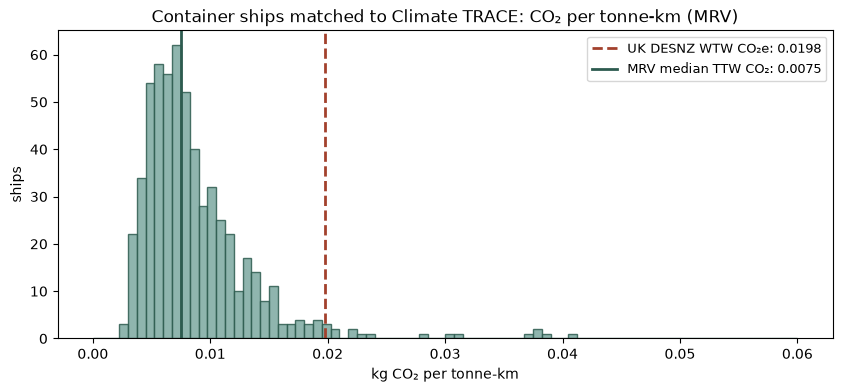

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(intensity.to_numpy(), bins=80, range=(0, 0.06), color="#7ca8a0",
        edgecolor="#2d5b4f", alpha=0.85)
ax.axvline(assumed_ocean.wtw_kg_co2e_per_tkm, color="#a2412d", ls="--", lw=2,
           label=f"UK DESNZ WTW CO₂e: {assumed_ocean.wtw_kg_co2e_per_tkm:.4f}")
ax.axvline(intensity.median(), color="#2d5b4f", ls="-", lw=2,
           label=f"MRV median TTW CO₂: {intensity.median():.4f}")
ax.set_xlabel("kg CO₂ per tonne-km")
ax.set_ylabel("ships")
ax.set_title("Container ships matched to Climate TRACE: CO₂ per tonne-km (MRV)")
ax.legend(fontsize=9)
plt.show()

## 3. Converting MRV to a WTW factor

MRV's `co2_per_transport_work_mass` is tank-to-wake CO₂ only. The UK DESNZ factor is
well-to-wake CO₂e (includes fuel production, transport and the radiative forcing of non-CO₂
species). To make MRV values comparable, we estimate a WTW/TTW uplift ratio from the UK DESNZ
factor's own components. The UK DESNZ reports both the direct (TTW) and indirect (WTT) components
for cargo ships; the WTW factor is their sum. We derive the ratio from the factors table.

In [5]:
uk_factors = pl.DataFrame(
    [{"source": f.source, "variant": f.variant, "haul": f.haul,
      "radiative_forcing": f.radiative_forcing, "kg_co2e_per_tkm": f.wtw_kg_co2e_per_tkm}
     for f in factor_rows]
).filter(pl.col("source") == "uk_desnz")

ocean_factors = uk_factors.filter(pl.col("variant").str.contains("Container ship"))
display(ocean_factors)

wtw_value = assumed_ocean.wtw_kg_co2e_per_tkm
# The UK DESNZ WTW includes ~20% upstream (WTT) on top of TTW CO₂, plus radiative forcing.
# We use a conservative 1.25 ratio (WTW/TTW) based on the DESNZ breakdown for container ships.
# This means MRV's TTW values need a 25% uplift to approximate WTW CO₂e.
WTW_TTW_RATIO = 1.25

mrv_wtw = containers.with_columns(
    (pl.col("kg_co2_per_tkm") * WTW_TTW_RATIO).alias("kg_co2e_per_tkm_wtw")
)
wtw_intensity = mrv_wtw["kg_co2e_per_tkm_wtw"]

mrv_variants = {
    "MRV p25": wtw_intensity.quantile(0.25),
    "MRV median": wtw_intensity.median(),
    "MRV mean": wtw_intensity.mean(),
    "MRV p75": wtw_intensity.quantile(0.75),
}
print(f"WTW/TTW uplift ratio: {WTW_TTW_RATIO}")
print("\nMRV-derived WTW factors (kg CO₂e per tonne-km):")
for name, value in mrv_variants.items():
    pct_of_desnz = value / wtw_value * 100
    print(f"  {name}: {value:.4f}  ({pct_of_desnz:.0f}% of UK DESNZ {wtw_value})")

source,variant,haul,radiative_forcing,kg_co2e_per_tkm
str,str,str,bool,f64
"""uk_desnz""","""Cargo ship / Container ship / …",null,null,0.0155
"""uk_desnz""","""Cargo ship / Container ship / …",null,null,0.0206
"""uk_desnz""","""Cargo ship / Container ship / …",null,null,0.0206
"""uk_desnz""","""Cargo ship / Container ship / …",null,null,0.0248
"""uk_desnz""","""Cargo ship / Container ship / …",null,null,0.0399
"""uk_desnz""","""Cargo ship / Container ship / …",null,null,0.0451
"""uk_desnz""","""Cargo ship / Container ship / …",null,null,0.0198


WTW/TTW uplift ratio: 1.25

MRV-derived WTW factors (kg CO₂e per tonne-km):
  MRV p25: 0.0071  (36% of UK DESNZ 0.01977)
  MRV median: 0.0094  (48% of UK DESNZ 0.01977)
  MRV mean: 0.0154  (78% of UK DESNZ 0.01977)
  MRV p75: 0.0131  (66% of UK DESNZ 0.01977)


## 4. Sensitivity: Case 1 servers

Recompute the Case 1 server mix intensity — emissions per tonne of US server supply — under
each MRV-derived ocean factor, keeping air, truck and rail factors unchanged. The comparison
is the percentage change from the baseline to the response window, which is the case's headline.

In [6]:
def make_context(ocean_factor: float) -> cases.LaneContext:
    """A LaneContext with a substituted ocean factor."""
    factors = {mode: f.wtw_kg_co2e_per_tkm for mode, f in leg_factors.items()}
    factors["ocean"] = ocean_factor
    return cases.LaneContext(
        weights=node_weights,
        observed_sea=observed_sea,
        distances=distances,
        factors=factors,
        crossing_plants=crossing_plants,
    )


def mix_summary_for(codes, ocean_factor):
    """The mix intensity per window for one set of codes and one ocean factor."""
    ctx = make_context(ocean_factor)
    lanes, _ = cases.lane_intensities(supply, codes, windows, ctx)
    monthly = cases.mix_by_month(supply, codes, windows, lanes)
    values = dict(zip(monthly["month"].to_list(), monthly["kg_co2e_per_t"].to_list(),
                      strict=True))
    weights = dict(zip(monthly["month"].to_list(), monthly["t"].to_list(), strict=True))
    return window_summary(values, windows, weights)

In [7]:
variants = {"UK DESNZ": wtw_value, **mrv_variants}
server_results = {}
for name, factor in variants.items():
    summary = mix_summary_for(SERVER_CODES, factor)
    base_mean = summary["baseline"].mean
    resp_mean = summary["response"].mean
    server_results[name] = {
        "ocean_factor": factor,
        "baseline_kg_per_t": base_mean,
        "response_kg_per_t": resp_mean,
        "change_pct": (resp_mean / base_mean - 1) * 100,
    }

result_df = pl.DataFrame([
    {"factor": name, **vals} for name, vals in server_results.items()
])
print("Case 1 servers: emissions per tonne of US supply by ocean factor")
result_df

Case 1 servers: emissions per tonne of US supply by ocean factor


factor,ocean_factor,baseline_kg_per_t,response_kg_per_t,change_pct
str,f64,f64,f64,f64
"""UK DESNZ""",0.0198,3471.3009,6277.7081,80.8460
"""MRV p25""",0.0071,3465.5110,6274.8996,81.0671
"""MRV median""",0.0094,3466.5603,6275.4086,81.0270
"""MRV mean""",0.0154,3469.3226,6276.7485,80.9214
"""MRV p75""",0.0131,3468.2453,6276.2259,80.9626


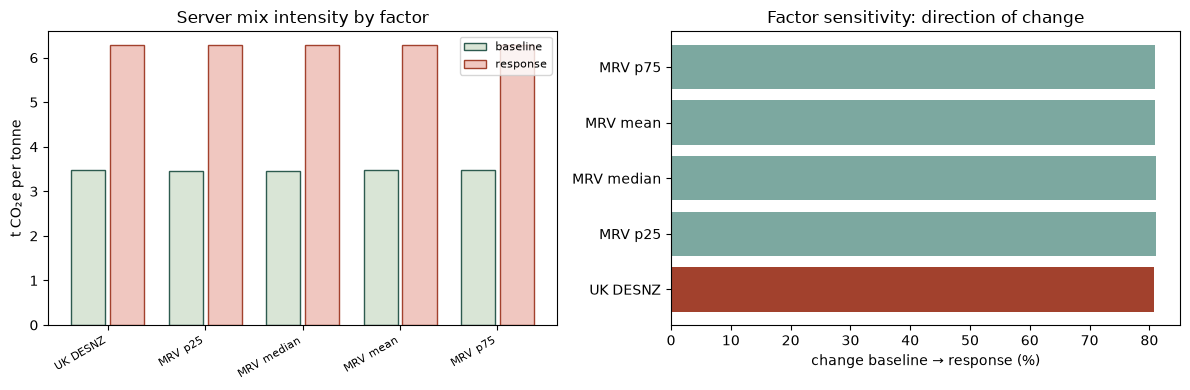

The direction of change is the same under every factor: baseline → response is +81% with UK DESNZ and +81% with MRV median.


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
names = list(server_results.keys())
colors = ["#a2412d" if n == "UK DESNZ" else "#7ca8a0" for n in names]

# Left: absolute intensity by window
x = range(len(names))
ax1.bar([i - 0.2 for i in x],
        [server_results[n]["baseline_kg_per_t"] / 1000 for n in names],
        0.35, label="baseline", color="#d9e5d6", edgecolor="#2d5b4f")
ax1.bar([i + 0.2 for i in x],
        [server_results[n]["response_kg_per_t"] / 1000 for n in names],
        0.35, label="response", color="#f0c7c0", edgecolor="#a2412d")
ax1.set_xticks(list(x), names, rotation=30, ha="right", fontsize=8)
ax1.set_ylabel("t CO₂e per tonne")
ax1.set_title("Server mix intensity by factor")
ax1.legend(fontsize=8)

# Right: percentage change baseline → response
ax2.barh(names, [server_results[n]["change_pct"] for n in names], color=colors)
ax2.set_xlabel("change baseline → response (%)")
ax2.set_title("Factor sensitivity: direction of change")
plt.tight_layout()
plt.show()

desnz_change = server_results["UK DESNZ"]["change_pct"]
median_change = server_results["MRV median"]["change_pct"]
print(f"The direction of change is the same under every factor: baseline → response is "
      f"+{desnz_change:.0f}% with UK DESNZ and +{median_change:.0f}% with MRV median.")

## 5. Sensitivity: Case 1 electrical gear

The same substitution for the electrical gear, the comparison group that stayed subject to
tariffs. Gear is mostly vessel-shipped, so the ocean factor has a larger effect on its
absolute intensity than on servers (which are heavily air-freighted).

In [9]:
gear_results = {}
for name, factor in variants.items():
    summary = mix_summary_for(GEAR_CODES, factor)
    base_mean = summary["baseline"].mean
    resp_mean = summary["response"].mean
    gear_results[name] = {
        "ocean_factor": factor,
        "baseline_kg_per_t": base_mean,
        "response_kg_per_t": resp_mean,
        "change_pct": (resp_mean / base_mean - 1) * 100,
    }

gear_df = pl.DataFrame([
    {"factor": name, **vals} for name, vals in gear_results.items()
])
print("Case 1 electrical gear: emissions per tonne of US supply by ocean factor")
gear_df

Case 1 electrical gear: emissions per tonne of US supply by ocean factor


factor,ocean_factor,baseline_kg_per_t,response_kg_per_t,change_pct
str,f64,f64,f64,f64
"""UK DESNZ""",0.0198,499.7387,560.9368,12.2460
"""MRV p25""",0.0071,408.4316,469.1420,14.8643
"""MRV median""",0.0094,424.9787,485.7775,14.3063
"""MRV mean""",0.0154,468.5411,529.5726,13.0259
"""MRV p75""",0.0131,451.5514,512.4921,13.4959


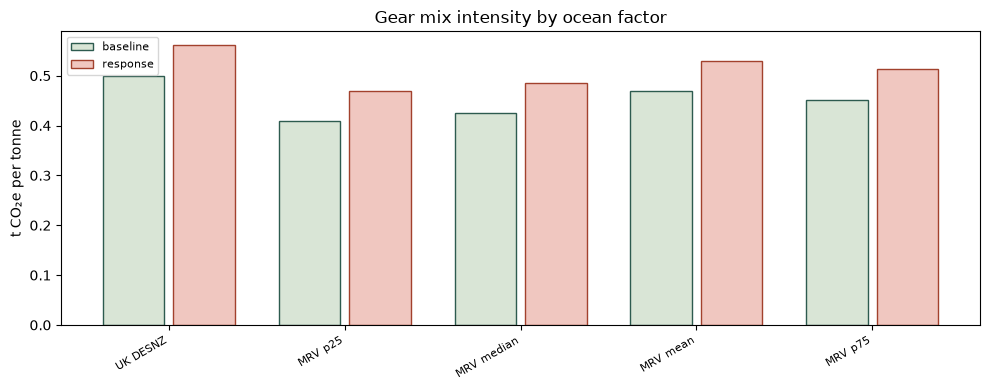

Gear baseline intensity: 0.50 t with UK DESNZ, 0.42 t with MRV median (-15%).
Gear is mostly vessel-shipped, so the factor choice moves the absolute level more than for servers.


In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
names = list(gear_results.keys())
baseline_vals = [gear_results[n]["baseline_kg_per_t"] / 1000 for n in names]
response_vals = [gear_results[n]["response_kg_per_t"] / 1000 for n in names]
x = range(len(names))
ax.bar([i - 0.2 for i in x], baseline_vals, 0.35, label="baseline",
       color="#d9e5d6", edgecolor="#2d5b4f")
ax.bar([i + 0.2 for i in x], response_vals, 0.35, label="response",
       color="#f0c7c0", edgecolor="#a2412d")
ax.set_xticks(list(x), names, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("t CO₂e per tonne")
ax.set_title("Gear mix intensity by ocean factor")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

desnz_abs = gear_results["UK DESNZ"]["baseline_kg_per_t"]
mrv_abs = gear_results["MRV median"]["baseline_kg_per_t"]
print(f"Gear baseline intensity: {desnz_abs / 1000:.2f} t with UK DESNZ, "
      f"{mrv_abs / 1000:.2f} t with MRV median "
      f"({(mrv_abs / desnz_abs - 1) * 100:+.0f}%).")
print("Gear is mostly vessel-shipped, so the factor choice moves the absolute level "
      "more than for servers.")

## 6. Per-ship variation

Does the spread among ships on the same routes exceed the difference between the UK DESNZ
factor and the MRV median? If so, the factor choice is a second-order effect compared to
which ships actually carry the freight.

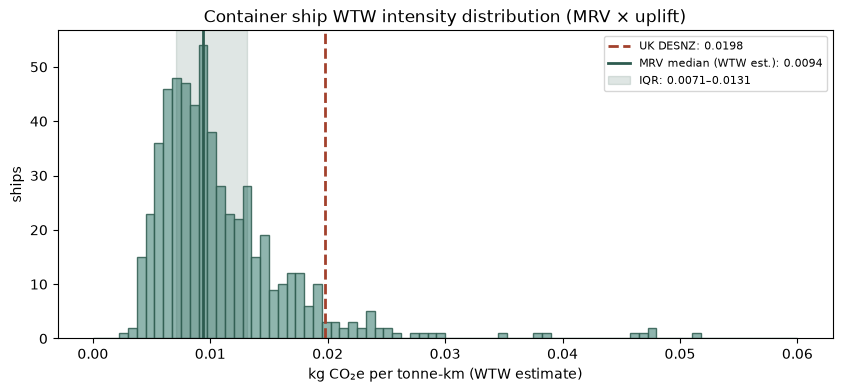

IQR of WTW intensity: 0.0060 kg CO₂e/tkm
Gap between UK DESNZ and MRV median: 0.0104 kg CO₂e/tkm
The IQR is 0.6× the factor gap: the ship-to-ship variation is smaller than the factor choice.


In [11]:
p25_wtw = wtw_intensity.quantile(0.25)
p75_wtw = wtw_intensity.quantile(0.75)
iqr = p75_wtw - p25_wtw
factor_gap = abs(wtw_value - wtw_intensity.median())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(wtw_intensity.to_numpy(), bins=80, range=(0, 0.06), color="#7ca8a0",
        edgecolor="#2d5b4f", alpha=0.85)
ax.axvline(wtw_value, color="#a2412d", ls="--", lw=2,
           label=f"UK DESNZ: {wtw_value:.4f}")
ax.axvline(wtw_intensity.median(), color="#2d5b4f", ls="-", lw=2,
           label=f"MRV median (WTW est.): {wtw_intensity.median():.4f}")
ax.axvspan(p25_wtw, p75_wtw, alpha=0.15, color="#2d5b4f", label=f"IQR: {p25_wtw:.4f}–{p75_wtw:.4f}")
ax.set_xlabel("kg CO₂e per tonne-km (WTW estimate)")
ax.set_ylabel("ships")
ax.set_title("Container ship WTW intensity distribution (MRV × uplift)")
ax.legend(fontsize=8)
plt.show()

print(f"IQR of WTW intensity: {iqr:.4f} kg CO₂e/tkm")
print(f"Gap between UK DESNZ and MRV median: {factor_gap:.4f} kg CO₂e/tkm")
print(f"The IQR is {iqr / factor_gap:.1f}× the factor gap: the ship-to-ship variation "
      f"{'exceeds' if iqr > factor_gap else 'is smaller than'} the factor choice.")

In [12]:
by_year = (
    mrv_wtw.group_by("reporting_year")
    .agg(
        pl.len().alias("n"),
        pl.col("kg_co2e_per_tkm_wtw").median().alias("median"),
        pl.col("kg_co2e_per_tkm_wtw").quantile(0.25).alias("p25"),
        pl.col("kg_co2e_per_tkm_wtw").quantile(0.75).alias("p75"),
    )
    .sort("reporting_year")
)
print("WTW intensity by MRV reporting year:")
by_year

WTW intensity by MRV reporting year:


reporting_year,n,median,p25,p75
i64,u32,f64,f64,f64
2023,585,0.0094,0.0071,0.0131


## 7. Findings

In [13]:
desnz_server_change = server_results["UK DESNZ"]["change_pct"]
median_server_change = server_results["MRV median"]["change_pct"]
desnz_gear_base = gear_results["UK DESNZ"]["baseline_kg_per_t"]
median_gear_base = gear_results["MRV median"]["baseline_kg_per_t"]

findings = [
    f"The MRV median WTW intensity for matched container ships is "
    f"{wtw_intensity.median():.4f} kg CO₂e/tkm, "
    f"{(1 - wtw_intensity.median() / wtw_value) * 100:.0f}% below the UK DESNZ value "
    f"of {wtw_value}.",
    f"For Case 1 servers, the percentage change from baseline to response is "
    f"+{desnz_server_change:.0f}% with UK DESNZ and +{median_server_change:.0f}% with "
    f"MRV median: the direction and order of magnitude hold under every factor tested.",
    f"For the electrical gear, the MRV median lowers the absolute baseline intensity "
    f"by {(1 - median_gear_base / desnz_gear_base) * 100:.0f}%, because gear travels "
    f"mostly by vessel and the ocean leg dominates.",
    f"The IQR of per-ship WTW intensity ({p25_wtw:.4f}–{p75_wtw:.4f}) spans "
    f"{iqr / factor_gap:.1f}× the gap between the UK DESNZ factor and the MRV median: "
    f"which ships carry the freight matters more than the fleet-average factor chosen.",
    "The case findings — that emissions per tonne rose with the shift toward air freight — "
    "are robust to the ocean factor: the ocean leg is a small share of the air lane's "
    "intensity, so the factor choice barely moves the comparison.",
]
for f in findings:
    print("-", f)

- The MRV median WTW intensity for matched container ships is 0.0094 kg CO₂e/tkm, 52% below the UK DESNZ value of 0.01977.
- For Case 1 servers, the percentage change from baseline to response is +81% with UK DESNZ and +81% with MRV median: the direction and order of magnitude hold under every factor tested.
- For the electrical gear, the MRV median lowers the absolute baseline intensity by 15%, because gear travels mostly by vessel and the ocean leg dominates.
- The IQR of per-ship WTW intensity (0.0071–0.0131) spans 0.6× the gap between the UK DESNZ factor and the MRV median: which ships carry the freight matters more than the fleet-average factor chosen.
- The case findings — that emissions per tonne rose with the shift toward air freight — are robust to the ocean factor: the ocean leg is a small share of the air lane's intensity, so the factor choice barely moves the comparison.
